## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Du

**Date:** October 13, 2026

### Q1. K-means clustering simulation

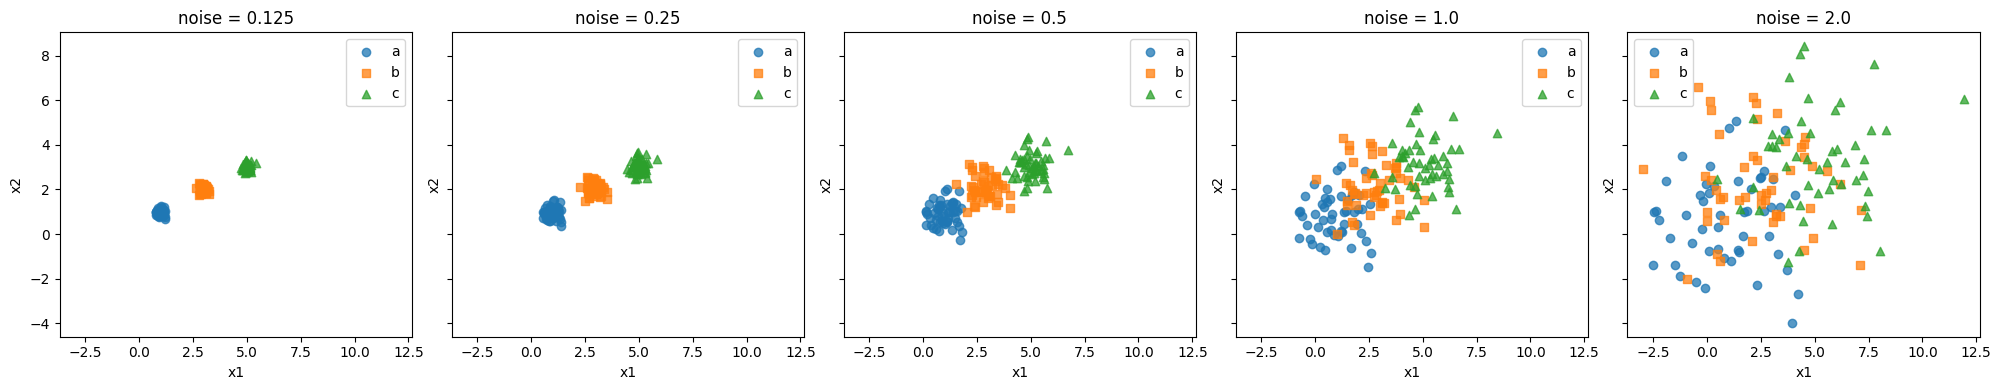

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Q1.1: create the five simulated datasets exactly as directed.
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0, ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    'noise = 0.125': df0_125,
    'noise = 0.25': df0_25,
    'noise = 0.5': df0_5,
    'noise = 1.0': df1_0,
    'noise = 2.0': df2_0,
}

# Q1.2: scatterplots by true group.
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
markers = {'a': 'o', 'b': 's', 'c': '^'}
for ax, (name, df) in zip(axes, datasets.items()):
    for group, group_df in df.groupby('group'):
        ax.scatter(group_df['x1'], group_df['x2'], label=group, alpha=0.75, marker=markers[group])
    ax.set_title(name)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend()
plt.tight_layout()
plt.show()

**Q1.2 answer.** At noise 0.125 and 0.25, the three groups are very visually distinct. At 0.5 they are still recognizable but begin to overlap. At noise 1.0 the overlap is substantial, and at 2.0 the groups are heavily mixed. Increasing the standard deviation spreads observations farther from their true centers, so the visual separation between clusters becomes weaker.

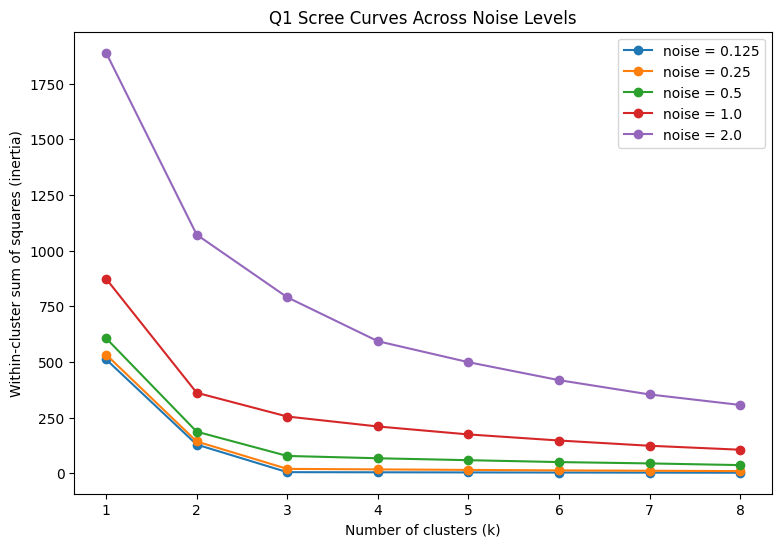

,noise = 0.125,noise = 0.25,noise = 0.5,noise = 1.0,noise = 2.0
k,,,,,
1,511.611829,533.252099,606.617962,873.690983,1889.202201
2,128.886790,142.720519,186.781235,361.588090,1071.812278
3,4.913219,19.652874,77.777015,254.882147,790.479064
4,4.333632,17.343286,67.364230,210.158530,593.190269
5,3.773758,15.060118,58.724471,174.455247,498.984278
6,3.263428,12.934612,50.241193,147.089886,418.292778
7,2.784334,11.256016,44.240675,123.563874,354.017620
8,2.409716,9.664537,36.627382,105.744158,306.862251


In [2]:
# Q1.3: scree curves for k = 1,...,8 on a common canvas.
k_values = range(1, 9)
q1_inertias = {}

plt.figure(figsize=(9, 6))
for name, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        model.fit(X)
        inertias.append(model.inertia_)
    q1_inertias[name] = inertias
    plt.plot(list(k_values), inertias, marker='o', label=name)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (inertia)')
plt.title('Q1 Scree Curves Across Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.show()

pd.DataFrame(q1_inertias, index=list(k_values)).rename_axis('k')

**Q1.3 answer.** With low noise, the scree curve drops sharply through about $k=3$ and then becomes almost flat, so the elbow at 3 is easy to identify. As noise increases, the total within-cluster variation increases and the curve becomes smoother. By noise 1.0 and especially 2.0, there is no single dramatic bend, so choosing $k$ from the elbow alone becomes much less definitive.

**Q1.4 answer.** The elbow is the point where adding another cluster stops buying a large reduction in within-cluster sum of squares. In the low-noise simulations, moving from one to two and then three clusters greatly reduces inertia because those clusters correspond to the three generating centers. Once $k=3$, additional centers mostly split already compact groups, so the improvement is small. With high noise the true groups overlap, so even the correct number of generating groups does not create as sharp a change in inertia.

### Q2. SIPRI military expenditure data

In [3]:
# Q2.1: load, filter to 2020, and remove rows with missing values.
sipri = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

sipri_2020 = sipri.loc[sipri['Year'] == 2020].copy()
sipri_2020 = sipri_2020.dropna().reset_index(drop=True)

print('Rows after filtering and dropna:', len(sipri_2020))
print(sipri_2020.dtypes)
sipri_2020.head()

Rows after filtering and dropna: 148
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


**Q2.1 answer.** After filtering to 2020 and dropping missing rows, there are 148 countries. The four measures used for clustering are already numeric, so I do not need additional recoding. The `Country` column stays as an identifier, and I do not include the old index or year in the clustering features.

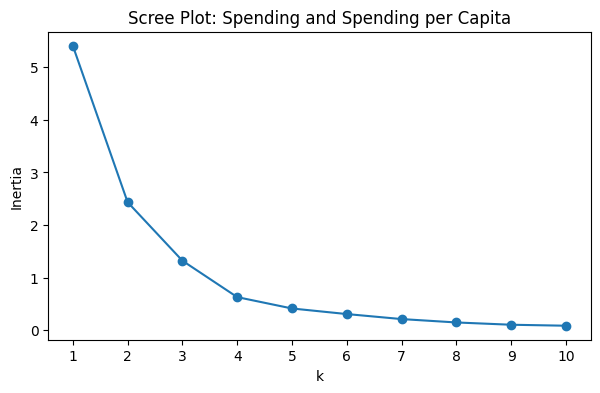

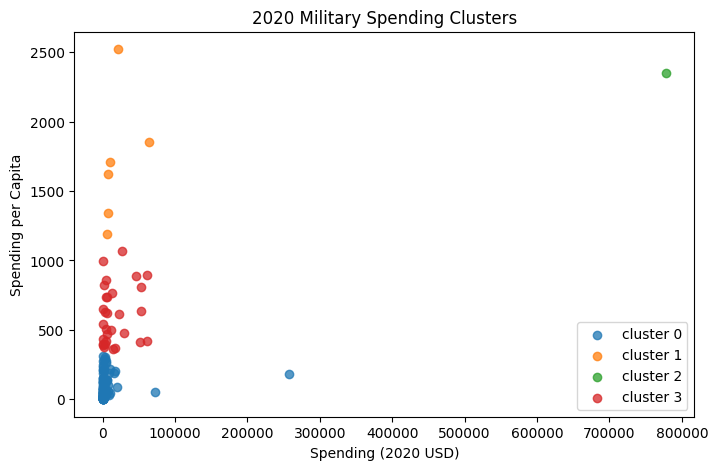

Spending (2020 USD)                                              \
                            count           mean           std            min   
spend_cluster                                                                   
0                           111.0    4859.185065  25405.739131       8.622460   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                             1.0  778397.200000           NaN  778397.200000   
3                            30.0   17077.591354  20583.053357     405.790494   

                                                                           \
                         25%            50%            75%            max   
spend_cluster                                                               
0                 130.010211     382.464677    2297.032353  257973.429834   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2              778397.200000  778397.200000  778397.200000  778397.200000   
3                2294.039665    5857.060906   26296.001003   61712.537169   

              Spending per Capita                                        \
                            count         mean         std          min   
spend_cluster                                                             
0                           111.0    80.061470   83.501824     0.580129   
1                             6.0  1706.721916  466.375705  1193.598730   
2                             1.0  2351.631858         NaN  2351.631858   
3                            30.0   607.478618  206.928757   362.467076   

                                                                   
                       25%          50%          75%          max  
spend_cluster                                                      
0                14.880549    47.056944   125.387558   314.201312  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2              2351.631858  2351.631858  2351.631858  2351.631858  
3               422.208252   579.004604   757.328513  1070.623322

Cluster sizes:
spend_cluster
0    111
1      6
2      1
3     30
Name: count, dtype: int64

United States:


,Country,Spending (2020 USD),Spending per Capita,spend_cluster
144,United States of America,778397.2,2351.631858,2


In [4]:
# Helper used for the required max-min normalization.
def minmax(series):
    return (series - series.min()) / (series.max() - series.min())

# Q2.2: Spending and Spending per Capita.
spend_cols = ['Spending (2020 USD)', 'Spending per Capita']
spend_norm = sipri_2020[spend_cols].apply(minmax)

spend_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(spend_norm)
    spend_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), spend_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.show()

# The elbow remains pronounced through roughly k=4.
k_spend = 4
spend_model = KMeans(n_clusters=k_spend, random_state=42, n_init=20)
sipri_2020['spend_cluster'] = spend_model.fit_predict(spend_norm)

plt.figure(figsize=(8, 5))
for cluster, part in sipri_2020.groupby('spend_cluster'):
    plt.scatter(part['Spending (2020 USD)'], part['Spending per Capita'], label=f'cluster {cluster}', alpha=0.75)
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('2020 Military Spending Clusters')
plt.legend()
plt.show()

display(sipri_2020.groupby('spend_cluster')[spend_cols].describe())
print('Cluster sizes:')
print(sipri_2020['spend_cluster'].value_counts().sort_index())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + spend_cols + ['spend_cluster']])

**Q2.2 answer.** The data are very right-skewed. Most countries fall into a large low-spending cluster, while several richer or larger military powers form higher-spending or higher-per-capita groups. The United States is the most extreme observation in total spending and is separated into its own cluster with this $k=4$ solution. A different cluster contains countries such as Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman that are notable for high spending per capita. This shows why normalization matters: otherwise total spending would dominate the distance calculation.

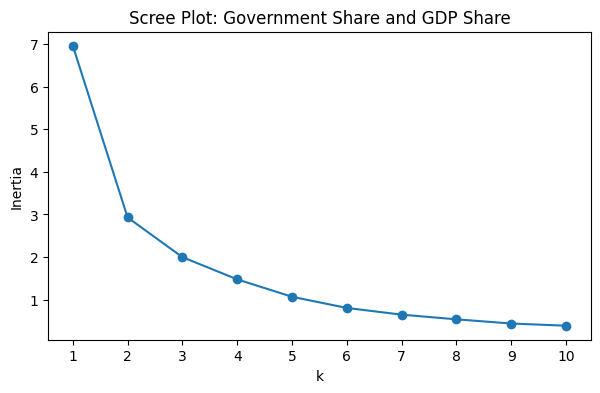

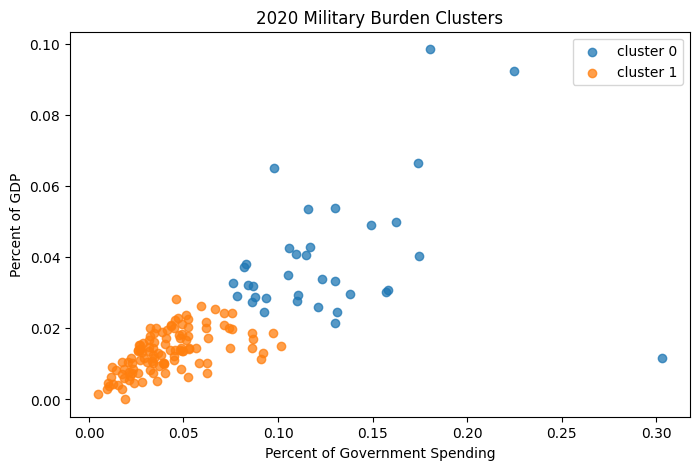

Percent of Government Spending                                \
                                       count      mean       std       min   
share_cluster                                                                
0                                       35.0  0.126456  0.046209  0.076005   
1                                      113.0  0.041394  0.020681  0.004896   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
share_cluster                                                          
0              0.093093  0.116052  0.143584  0.303027           35.0   
1              0.026783  0.038486  0.051496  0.101501          113.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
share_cluster                                                               
0              0.039433  0.018179  0.011742  0.028962  0.033281  0.042722   
1              0.013481  0.005966  0.000054  0.009147  0.013631  0.017830   

                         
                    max  
share_cluster            
0              0.098470  
1              0.028132

Cluster sizes:
share_cluster
0     35
1    113
Name: count, dtype: int64

United States:


,Country,Percent of Government Spending,Percent of GDP,share_cluster
144,United States of America,0.081976,0.037179,0


In [5]:
# Q2.3: Percent of Government Spending and Percent of GDP.
share_cols = ['Percent of Government Spending', 'Percent of GDP']
share_norm = sipri_2020[share_cols].apply(minmax)

share_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(share_norm)
    share_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), share_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: Government Share and GDP Share')
plt.show()

# Here the strongest bend occurs very early, around k=2.
k_share = 2
share_model = KMeans(n_clusters=k_share, random_state=42, n_init=20)
sipri_2020['share_cluster'] = share_model.fit_predict(share_norm)

plt.figure(figsize=(8, 5))
for cluster, part in sipri_2020.groupby('share_cluster'):
    plt.scatter(part['Percent of Government Spending'], part['Percent of GDP'], label=f'cluster {cluster}', alpha=0.75)
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.title('2020 Military Burden Clusters')
plt.legend()
plt.show()

display(sipri_2020.groupby('share_cluster')[share_cols].describe())
print('Cluster sizes:')
print(sipri_2020['share_cluster'].value_counts().sort_index())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + share_cols + ['share_cluster']])

**Q2.3 answer.** These clusters are different from part 2 because they describe military burden or priority rather than the absolute scale of the military budget. The higher-share cluster has countries that devote a relatively large fraction of GDP and/or government spending to the military. The United States falls in that higher-burden group, but it is not uniquely separated the way it is by total spending. Countries can therefore be small in dollars yet still have a high military burden, while some very large economies can spend many dollars without having an unusually high percentage.

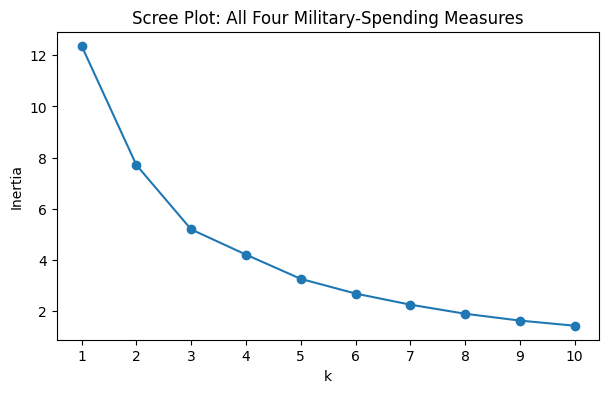

Cluster sizes:
all_cluster
0     31
1      6
2    111
Name: count, dtype: int64

Cluster means on original variables:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,8786.086602,212.689100,0.122985,0.033492
1,147964.582042,1875.150751,0.135351,0.062634
2,7086.472777,196.926833,0.040350,0.013419



United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,all_cluster
144,United States of America,778397.2,2351.631858,0.081976,0.037179,1


Cluster 0 sample/highest-spending members:
['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia', 'Ukraine', 'Iraq', 'Morocco', 'Myanmar']
Cluster 1 sample/highest-spending members:
['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']
Cluster 2 sample/highest-spending members:
['China', 'United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Brazil', 'Turkey', 'Spain', 'Poland']


In [6]:
# Q2.4: all four numeric variables together.
all_cols = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]
all_norm = sipri_2020[all_cols].apply(minmax)

all_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(all_norm)
    all_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), all_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Military-Spending Measures')
plt.show()

k_all = 3
all_model = KMeans(n_clusters=k_all, random_state=42, n_init=20)
sipri_2020['all_cluster'] = all_model.fit_predict(all_norm)

print('Cluster sizes:')
print(sipri_2020['all_cluster'].value_counts().sort_index())
print()
print('Cluster means on original variables:')
display(sipri_2020.groupby('all_cluster')[all_cols].mean())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + all_cols + ['all_cluster']])

for cluster in sorted(sipri_2020['all_cluster'].unique()):
    members = sipri_2020.loc[sipri_2020['all_cluster'] == cluster].sort_values('Spending (2020 USD)', ascending=False)
    print(f'Cluster {cluster} sample/highest-spending members:')
    print(members['Country'].head(12).tolist())

**Q2.4 answer.** Using all four normalized measures combines scale with burden. With $k=3$, one group contains most lower-burden countries, another contains countries with relatively high military shares, and a small high-intensity/high-per-capita group contains the most extreme cases. The United States moves from being a one-country spending cluster to a small cluster with countries such as Saudi Arabia, Israel, Singapore, Kuwait, and Oman because the percentage variables now matter too. This result is a compromise between the absolute-spending structure in part 2 and the burden structure in part 3.

**Q2.5 answer.** Yes. K-means is useful here as an exploratory summary because it separates countries with very different military-spending profiles and makes the outliers easy to identify. It also shows that “high military spending” can mean different things: high total dollars, high per-capita spending, or a high share of national resources. The clusters should not be treated as natural or permanent categories, however. The chosen $k$ is subjective, K-means is sensitive to scaling and outliers, and countries near a boundary can change groups when different variables are used.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]